In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical analysis
from scipy import stats

# Machine learning
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# File handling
import os
import warnings

warnings.filterwarnings('ignore')

# Visualization settings
sns.set_style('whitegrid')

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 100

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.2f}'.format)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Zomato CSV file loading
df = pd.read_csv('zomato.csv')

In [ ]:
# Top 5 Rows and columns
df.head()

,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7/5,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari
4,https://www.zomato.com/bangalore/grand-village...,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8/5,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari


In [ ]:

# Check unique values:

for col in df.columns:
    print(f"\nColumn: {col}")
    print("Unique Values:", df[col].nunique())


Column: url
Unique Values: 51717

Column: address
Unique Values: 11495

Column: name
Unique Values: 8792

Column: online_order
Unique Values: 2

Column: book_table
Unique Values: 2

Column: rate
Unique Values: 64

Column: votes
Unique Values: 2328

Column: phone
Unique Values: 14926

Column: location
Unique Values: 93

Column: rest_type
Unique Values: 93

Column: dish_liked
Unique Values: 5271

Column: cuisines
Unique Values: 2723

Column: approx_cost(for two people)
Unique Values: 70

Column: reviews_list
Unique Values: 22513

Column: menu_item
Unique Values: 9098

Column: listed_in(type)
Unique Values: 7

Column: listed_in(city)
Unique Values: 30


In [ ]:
# Last 5 Rows and columns
df.tail()

,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
51712,https://www.zomato.com/bangalore/best-brews-fo...,"Four Points by Sheraton Bengaluru, 43/3, White...",Best Brews - Four Points by Sheraton Bengaluru...,No,No,3.6 /5,27,080 40301477,Whitefield,Bar,NaN,Continental,"1,500","[('Rated 5.0', ""RATED\n Food and service are ...",[],Pubs and bars,Whitefield
51713,https://www.zomato.com/bangalore/vinod-bar-and...,"Number 10, Garudachar Palya, Mahadevapura, Whi...",Vinod Bar And Restaurant,No,No,NaN,0,+91 8197675843,Whitefield,Bar,NaN,Finger Food,600,[],[],Pubs and bars,Whitefield
51714,https://www.zomato.com/bangalore/plunge-sherat...,Sheraton Grand Bengaluru Whitefield Hotel & Co...,Plunge - Sheraton Grand Bengaluru Whitefield H...,No,No,NaN,0,NaN,Whitefield,Bar,NaN,Finger Food,"2,000",[],[],Pubs and bars,Whitefield
51715,https://www.zomato.com/bangalore/chime-sherato...,Sheraton Grand Bengaluru Whitefield Hotel & Co...,Chime - Sheraton Grand Bengaluru Whitefield Ho...,No,Yes,4.3 /5,236,080 49652769,"ITPL Main Road, Whitefield",Bar,"Cocktails, Pizza, Buttermilk",Finger Food,"2,500","[('Rated 4.0', 'RATED\n Nice and friendly pla...",[],Pubs and bars,Whitefield
51716,https://www.zomato.com/bangalore/the-nest-the-...,"ITPL Main Road, KIADB Export Promotion Industr...",The Nest - The Den Bengaluru,No,No,3.4 /5,13,+91 8071117272,"ITPL Main Road, Whitefield","Bar, Casual Dining",NaN,"Finger Food, North Indian, Continental","1,500","[('Rated 5.0', 'RATED\n Great ambience , look...",[],Pubs and bars,Whitefield


In [ ]:
# Data information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51717 entries, 0 to 51716
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   url                          51717 non-null  str  
 1   address                      51717 non-null  str  
 2   name                         51717 non-null  str  
 3   online_order                 51717 non-null  str  
 4   book_table                   51717 non-null  str  
 5   rate                         43942 non-null  str  
 6   votes                        51717 non-null  int64
 7   phone                        50509 non-null  str  
 8   location                     51696 non-null  str  
 9   rest_type                    51490 non-null  str  
 10  dish_liked                   23639 non-null  str  
 11  cuisines                     51672 non-null  str  
 12  approx_cost(for two people)  51371 non-null  str  
 13  reviews_list                 51717 non-null  str  
 14  m

In [ ]:
# Columns of Files
df.columns

Index(['url', 'address', 'name', 'online_order', 'book_table', 'rate', 'votes',
       'phone', 'location', 'rest_type', 'dish_liked', 'cuisines',
       'approx_cost(for two people)', 'reviews_list', 'menu_item',
       'listed_in(type)', 'listed_in(city)'],
      dtype='str')

In [ ]:
# Drop Columns
df.drop(columns=['url','address','name','phone','location','rest_type','dish_liked','cuisines','reviews_list',])

,online_order,book_table,rate,votes,approx_cost(for two people),menu_item,listed_in(type),listed_in(city)
0,Yes,Yes,4.1/5,775,800,[],Buffet,Banashankari
1,Yes,No,4.1/5,787,800,[],Buffet,Banashankari
2,Yes,No,3.8/5,918,800,[],Buffet,Banashankari
3,No,No,3.7/5,88,300,[],Buffet,Banashankari
4,No,No,3.8/5,166,600,[],Buffet,Banashankari
...,...,...,...,...,...,...,...,...
51712,No,No,3.6 /5,27,"1,500",[],Pubs and bars,Whitefield
51713,No,No,NaN,0,600,[],Pubs and bars,Whitefield
51714,No,No,NaN,0,"2,000",[],Pubs and bars,Whitefield
51715,No,Yes,4.3 /5,236,"2,500",[],Pubs and bars,Whitefield


In [ ]:
# Reset index
df.drop(columns=['url','address','name','phone','location','rest_type','dish_liked','cuisines','reviews_list',]).reset_index()

,index,online_order,book_table,rate,votes,approx_cost(for two people),menu_item,listed_in(type),listed_in(city)
0,0,Yes,Yes,4.1/5,775,800,[],Buffet,Banashankari
1,1,Yes,No,4.1/5,787,800,[],Buffet,Banashankari
2,2,Yes,No,3.8/5,918,800,[],Buffet,Banashankari
3,3,No,No,3.7/5,88,300,[],Buffet,Banashankari
4,4,No,No,3.8/5,166,600,[],Buffet,Banashankari
...,...,...,...,...,...,...,...,...,...
51712,51712,No,No,3.6 /5,27,"1,500",[],Pubs and bars,Whitefield
51713,51713,No,No,NaN,0,600,[],Pubs and bars,Whitefield
51714,51714,No,No,NaN,0,"2,000",[],Pubs and bars,Whitefield
51715,51715,No,Yes,4.3 /5,236,"2,500",[],Pubs and bars,Whitefield


In [ ]:
# Check Rows and columns
df.shape

(51717, 17)

In [11]:
# Total missing values
missing_values = df.isnull().sum()

# Missing percentage
missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

# Create missing value report
missing_report = pd.DataFrame({
    'Missing_Count': missing_values,
    'Missing_Percentage': missing_percentage
})

missing_report = missing_report.sort_values(
    by='Missing_Percentage',
    ascending=False
)

display(missing_report)

,Missing_Count,Missing_Percentage
dish_liked,28078,54.29
rate,7775,15.03
phone,1208,2.34
approx_cost(for two people),346,0.67
rest_type,227,0.44
cuisines,45,0.09
location,21,0.04
url,0,0.00
address,0,0.00
votes,0,0.00


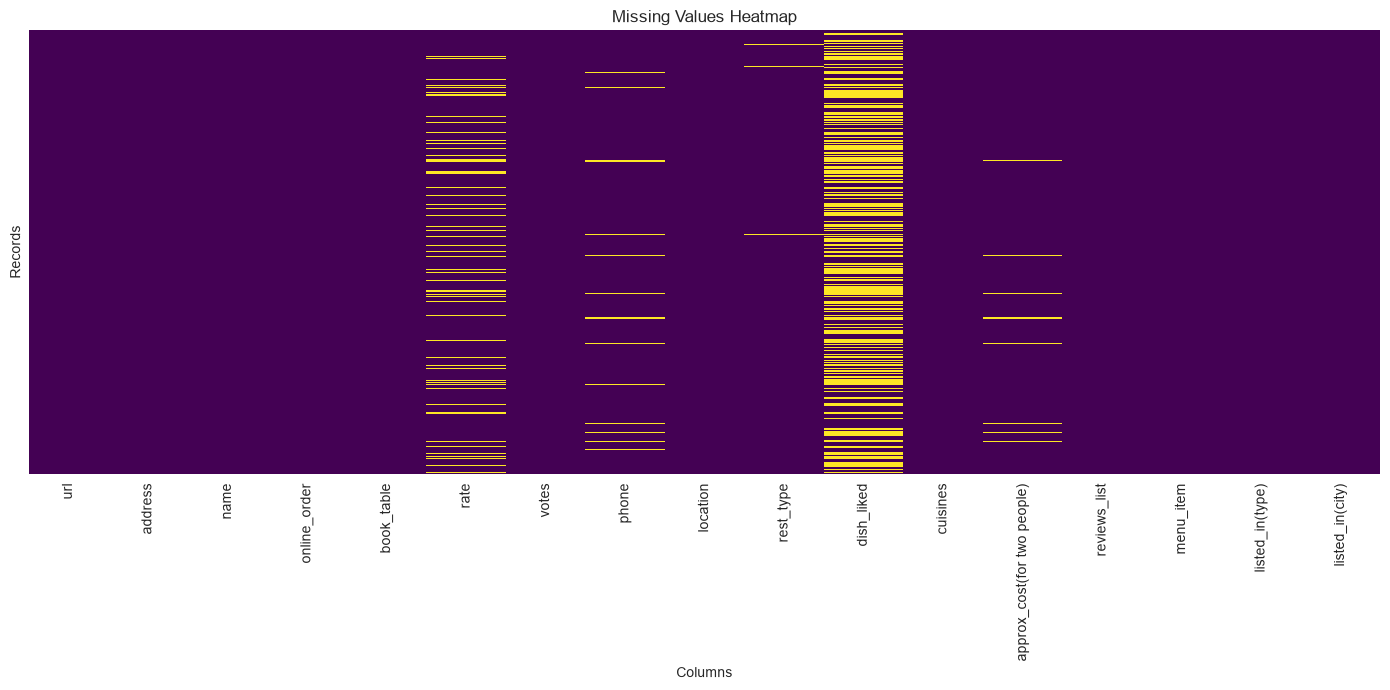

In [12]:
plt.figure(figsize=(14, 7))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap='viridis'
)

plt.title('Missing Values Heatmap')
plt.xlabel('Columns')
plt.ylabel('Records')

plt.tight_layout()
# plt.savefig('outputs/charts/01_missing_values.png')
plt.show()

In [13]:
df['name'] = (
    df['name']
    .astype('string')
    .str.strip()
)

df['name'] = df['name'].replace('', pd.NA)

print(df['name'].head())

0                    Jalsa
1           Spice Elephant
2          San Churro Cafe
3    Addhuri Udupi Bhojana
4            Grand Village
Name: name, dtype: string


In [14]:
# Create a copy of original rating
df['rate_original'] = df['rate']

# Remove /5 and spaces
df['rate'] = (
    df['rate']
    .astype('string')
    .str.strip()
    .str.replace('/5', '', regex=False)
)

# Convert to numeric
df['rate'] = pd.to_numeric(
    df['rate'],
    errors='coerce'
)

# Invalid rating range becomes missing
df.loc[
    ~df['rate'].between(0, 5),
    'rate'
] = np.nan

print(df['rate'].head(10))

print("Missing Ratings:", df['rate'].isnull().sum())

0   4.10
1   4.10
2   3.80
3   3.70
4   3.80
5   3.80
6   3.60
7   4.60
8   4.00
9   4.20
Name: rate, dtype: Float64
Missing Ratings: 10052


In [15]:
cost_col = 'approx_cost(for two people)'

# Remove commas and spaces
df[cost_col] = (
    df[cost_col]
    .astype('string')
    .str.replace(',', '', regex=False)
    .str.strip()
)

# Convert into numeric
df[cost_col] = pd.to_numeric(
    df[cost_col],
    errors='coerce'
)

print(df[cost_col].head(10))

print(df[cost_col].describe())

0    800
1    800
2    800
3    300
4    600
5    600
6    800
7    600
8    700
9    550
Name: approx_cost(for two people), dtype: Int64
count   51371.00
mean      555.43
std       438.85
min        40.00
25%       300.00
50%       400.00
75%       650.00
max      6000.00
Name: approx_cost(for two people), dtype: Float64


In [16]:
# Inspect original values
print(df['online_order'].value_counts(dropna=False))

# Standardize
df['online_order'] = (
    df['online_order']
    .astype('string')
    .str.strip()
    .str.lower()
)

# Convert into binary
df['online_order'] = df['online_order'].map({
    'yes': 1,
    'no': 0
})

print(df['online_order'].value_counts(dropna=False))

online_order
Yes    30444
No     21273
Name: count, dtype: int64
online_order
1    30444
0    21273
Name: count, dtype: int64


In [17]:
print(df['book_table'].value_counts(dropna=False))

df['book_table'] = (
    df['book_table']
    .astype('string')
    .str.strip()
    .str.lower()
)

df['book_table'] = df['book_table'].map({
    'yes': 1,
    'no': 0
})

print(df['book_table'].value_counts(dropna=False))

book_table
No     45268
Yes     6449
Name: count, dtype: int64
book_table
0    45268
1     6449
Name: count, dtype: int64


In [ ]:
#Feature Engineering : 
df['rating_category'] = pd.cut(
    df['rate'],
    bins=[0, 2, 3, 4, 5],
    labels=[
        'Poor',
        'Average',
        'Good',
        'Excellent'
    ],
    include_lowest=True
)
print(df['rating_category'].value_counts())

rating_category
Good         29169
Excellent     9216
Average       3264
Poor            16
Name: count, dtype: int64


In [19]:
df['price_category'] = pd.cut(
    df[cost_col],
    bins=[0, 500, 1000, 2000, 5000, np.inf],
    labels=[
        'Budget',
        'Affordable',
        'Moderate',
        'Expensive',
        'Premium'
    ]
)
print(df['price_category'].value_counts())

price_category
Budget        33283
Affordable    12808
Moderate       4656
Expensive       622
Premium           2
Name: count, dtype: int64


In [20]:
df['online_order_label'] = df['online_order'].map({
    1: 'Online Available',
    0: 'Online Not Available'
})

df['table_booking_label'] = df['book_table'].map({
    1: 'Booking Available',
    0: 'Booking Not Available'
})

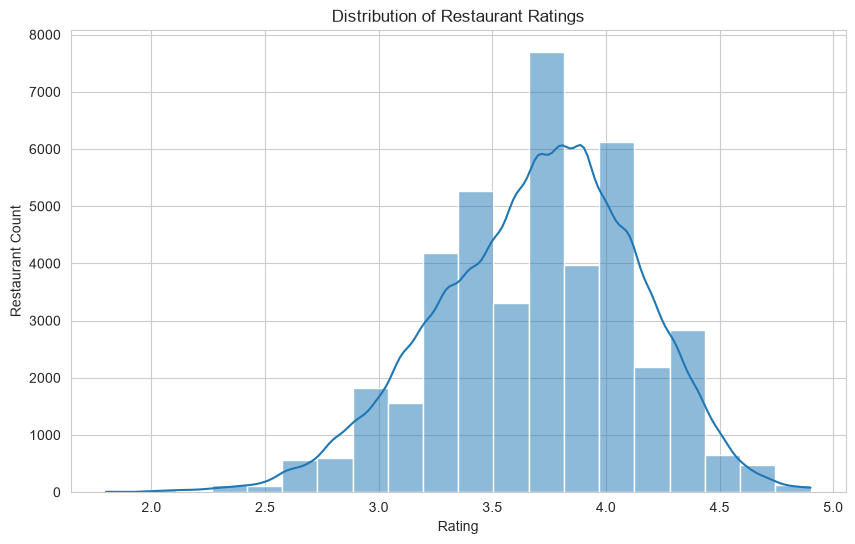

In [21]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='rate',
    bins=20,
    kde=True
)

plt.title('Distribution of Restaurant Ratings')
plt.xlabel('Rating')
plt.ylabel('Restaurant Count')

#plt.savefig('outputs/charts/02_rating_distribution.png')
plt.show()

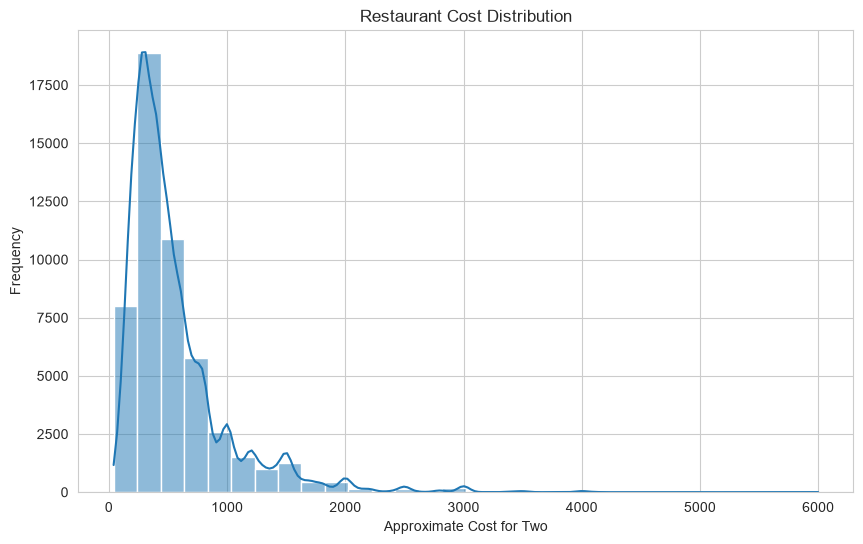

In [22]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x=cost_col,
    bins=30,
    kde=True
)

plt.title('Restaurant Cost Distribution')
plt.xlabel('Approximate Cost for Two')
plt.ylabel('Frequency')

plt.show()

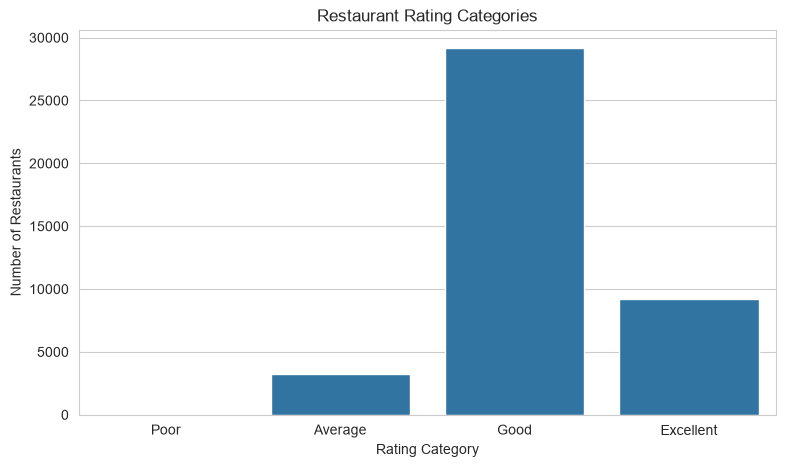

In [23]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='rating_category',
    order=[
        'Poor',
        'Average',
        'Good',
        'Excellent'
    ]
)

plt.title('Restaurant Rating Categories')
plt.xlabel('Rating Category')
plt.ylabel('Number of Restaurants')

plt.show()

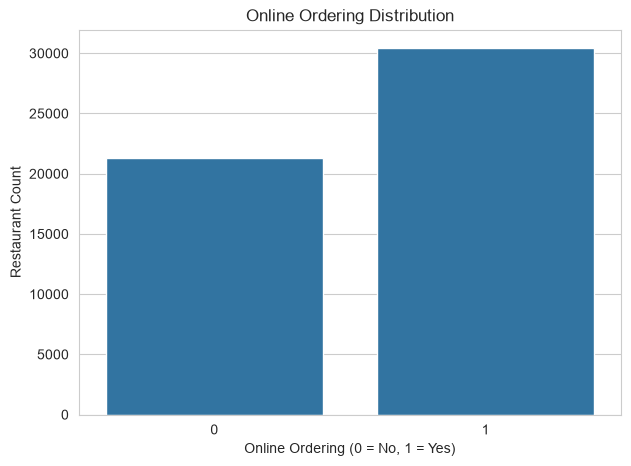

In [24]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='online_order'
)

plt.title('Online Ordering Distribution')
plt.xlabel('Online Ordering (0 = No, 1 = Yes)',)
plt.ylabel('Restaurant Count')

plt.show()

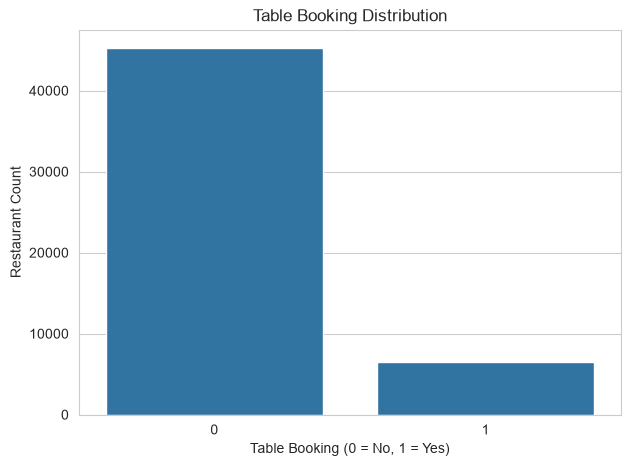

In [25]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='book_table'
)

plt.title('Table Booking Distribution')
plt.xlabel('Table Booking (0 = No, 1 = Yes)')
plt.ylabel('Restaurant Count')

plt.show()

              mean  median  count
online_order                     
0             3.66    3.70  14459
1             3.72    3.80  27206


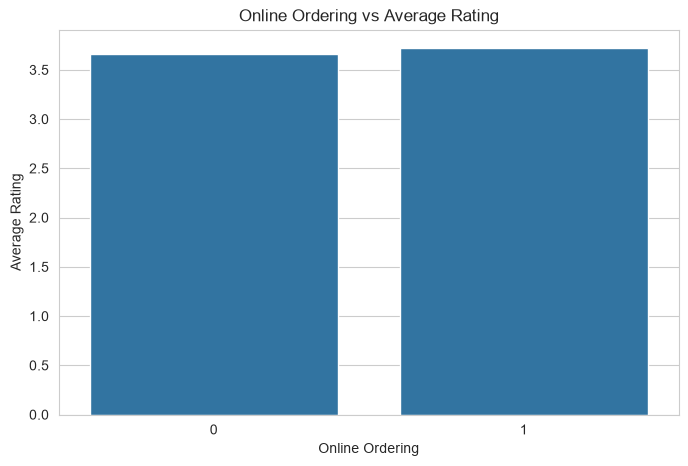

In [26]:
online_rating = (
    df.groupby('online_order', dropna=True)['rate']
    .agg(['mean', 'median', 'count'])
)

print(online_rating)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='online_order',
    y='rate',
    errorbar=None
)

plt.title('Online Ordering vs Average Rating')
plt.xlabel('Online Ordering')
plt.ylabel('Average Rating')

plt.show()

            mean  median  count
book_table                     
0           3.62    3.70  35361
1           4.14    4.20   6304


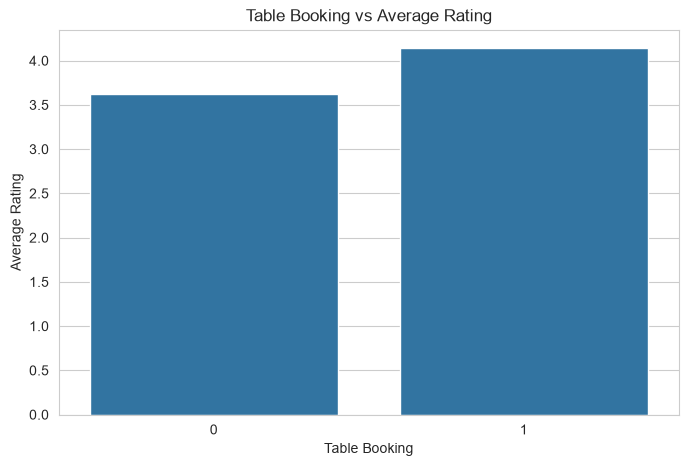

In [27]:
booking_rating = (
    df.groupby('book_table')['rate']
    .agg(['mean', 'median', 'count'])
)

print(booking_rating)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='book_table',
    y='rate',
    errorbar=None
)

plt.title('Table Booking vs Average Rating')
plt.xlabel('Table Booking')
plt.ylabel('Average Rating')

plt.show()

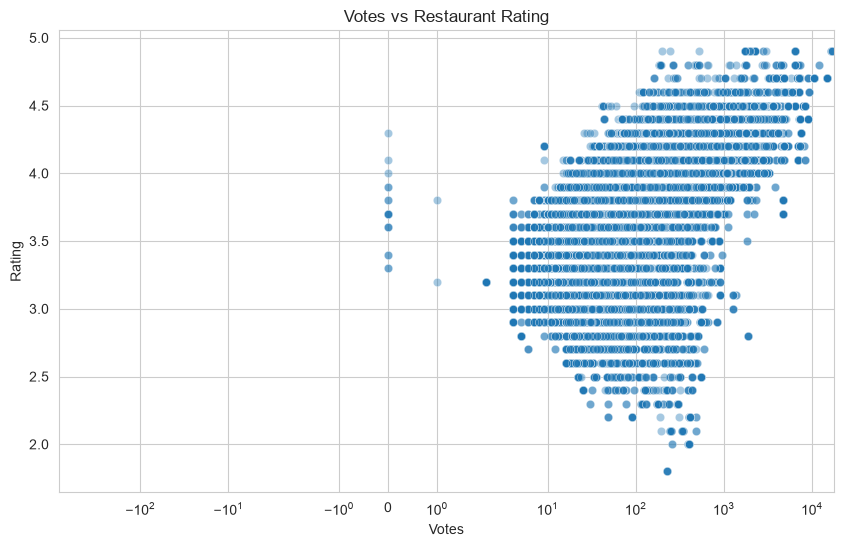

In [28]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='votes',
    y='rate',
    alpha=0.4
)

plt.xscale('symlog')

plt.title('Votes vs Restaurant Rating')
plt.xlabel('Votes')
plt.ylabel('Rating')

plt.show()

book_table        0     1
online_order             
0             18629  2644
1             26639  3805


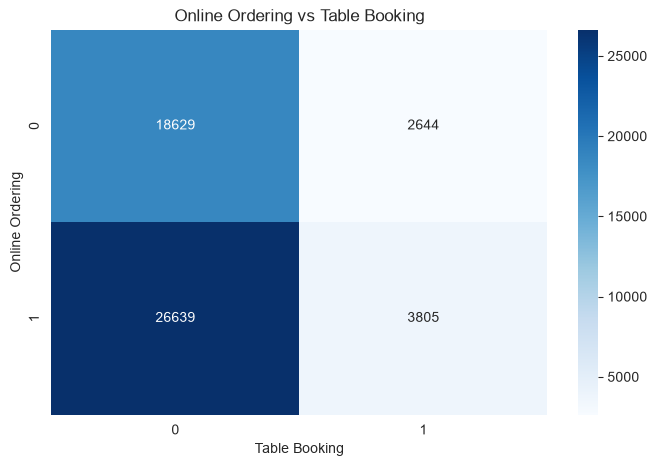

In [29]:
order_booking = pd.crosstab(
    df['online_order'],
    df['book_table']
)

print(order_booking)

plt.figure(figsize=(8, 5))

sns.heatmap(
    order_booking,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Online Ordering vs Table Booking')
plt.xlabel('Table Booking')
plt.ylabel('Online Ordering')

plt.show()

location
BTM                      5124
HSR                      2523
Koramangala 5th Block    2504
JP Nagar                 2235
Whitefield               2144
Indiranagar              2083
Jayanagar                1926
Marathahalli             1846
Bannerghatta Road        1630
Bellandur                1286
Electronic City          1258
Koramangala 1st Block    1238
Brigade Road             1218
Koramangala 7th Block    1181
Koramangala 6th Block    1156
Name: count, dtype: int64


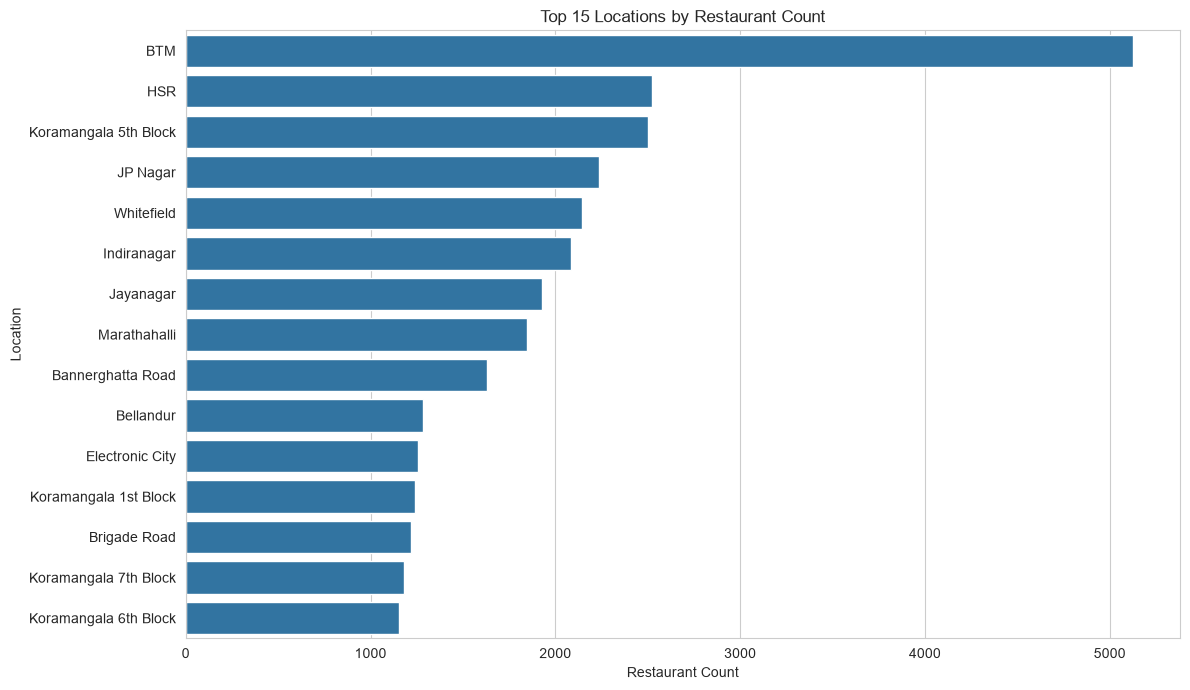

In [30]:
top_locations = (
    df[df['location'] != 'Unknown']
    ['location']
    .value_counts()
    .head(15)
)

print(top_locations)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_locations.values,
    y=top_locations.index
)

plt.title('Top 15 Locations by Restaurant Count')
plt.xlabel('Restaurant Count')
plt.ylabel('Location')

plt.tight_layout()
plt.show()

In [31]:
location_rating = (
    df[df['location'] != 'Unknown']
    .groupby('location')
    .agg(
        avg_rating=('rate', 'mean'),
        total_votes=('votes', 'sum'),
        restaurant_count=('name', 'count')
    )
)

# Filter locations with at least 30 records
location_rating = location_rating[
    location_rating['restaurant_count'] >= 30
]

location_rating = location_rating.sort_values(
    by='avg_rating',
    ascending=False
)

print(location_rating.head(15))

                       avg_rating  total_votes  restaurant_count
location                                                        
Lavelle Road                 4.14       506186               529
Koramangala 3rd Block        4.02       125159               216
St. Marks Road               4.02       266099               352
Koramangala 5th Block        4.01      2219506              2504
Church Street                3.99       594979               569
Koramangala 4th Block        3.92       685156              1017
Cunningham Road              3.90       287873               491
Residency Road               3.86       291954               675
MG Road                      3.86       432111               918
Koramangala 7th Block        3.85       495324              1181
Sadashiv Nagar               3.84        19727                63
Indiranagar                  3.83      1196007              2083
Richmond Road                3.82       119414               812
Infantry Road            

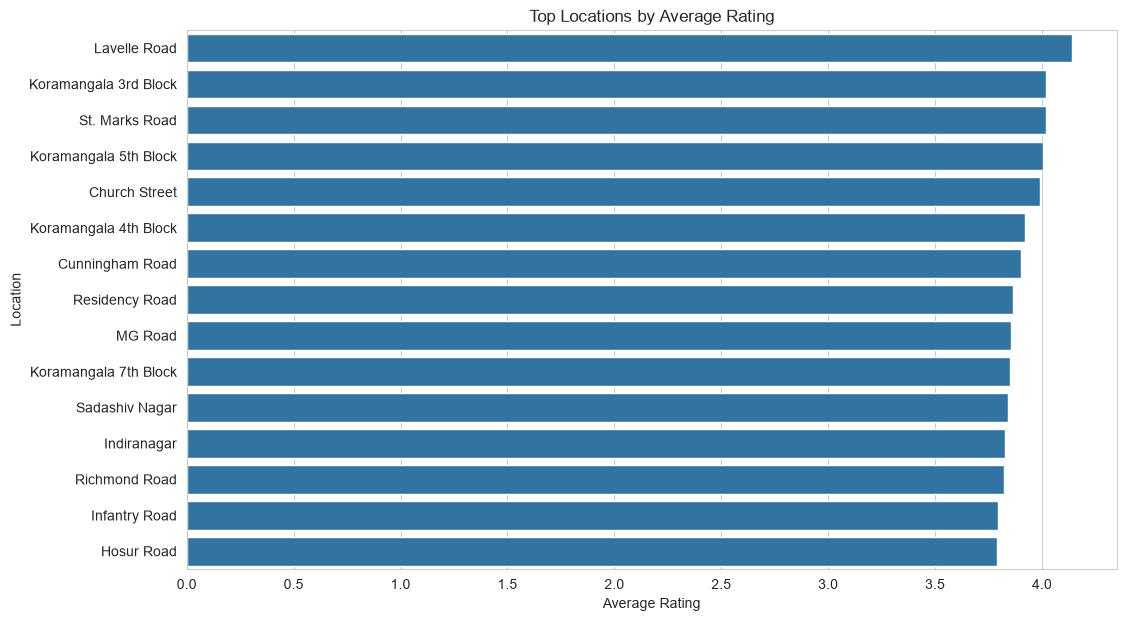

In [32]:
top_rated_locations = location_rating.head(15)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_rated_locations['avg_rating'],
    y=top_rated_locations.index
)

plt.title('Top Locations by Average Rating')
plt.xlabel('Average Rating')
plt.ylabel('Location')

plt.show()

In [33]:
cuisine_df = df[
    ['name', 'location', 'rate', 'votes',
     cost_col, 'cuisines']
].copy()

cuisine_df['cuisines'] = (
    cuisine_df['cuisines']
    .str.split(',')
)

cuisine_df = cuisine_df.explode('cuisines')

cuisine_df['cuisines'] = (
    cuisine_df['cuisines']
    .str.strip()
)

cuisine_df = cuisine_df[
    cuisine_df['cuisines'].notna() &
    (cuisine_df['cuisines'] != '') &
    (cuisine_df['cuisines'] != 'Unknown')
]

display(cuisine_df.head(10))

,name,location,rate,votes,approx_cost(for two people),cuisines
0,Jalsa,Banashankari,4.10,775,800,North Indian
0,Jalsa,Banashankari,4.10,775,800,Mughlai
0,Jalsa,Banashankari,4.10,775,800,Chinese
1,Spice Elephant,Banashankari,4.10,787,800,Chinese
1,Spice Elephant,Banashankari,4.10,787,800,North Indian
1,Spice Elephant,Banashankari,4.10,787,800,Thai
2,San Churro Cafe,Banashankari,3.80,918,800,Cafe
2,San Churro Cafe,Banashankari,3.80,918,800,Mexican
2,San Churro Cafe,Banashankari,3.80,918,800,Italian
3,Addhuri Udupi Bhojana,Banashankari,3.70,88,300,South Indian


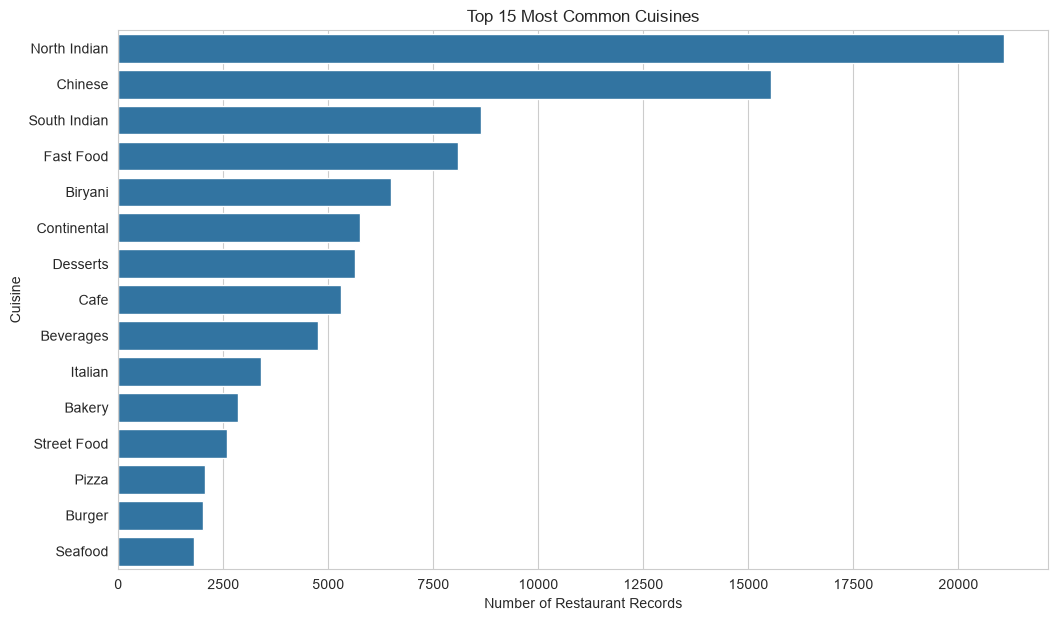

In [37]:
plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_cuisines.values,
    y=top_cuisines.index
)

plt.title('Top 15 Most Common Cuisines')
plt.xlabel('Number of Restaurant Records')
plt.ylabel('Cuisine')

plt.show()

In [ ]:
cuisine_rating = (
    cuisine_df
    .groupby('cuisines')
    .agg(
        avg_rating=('rate', 'mean'),
        total_votes=('votes', 'sum'),
        restaurant_count=('name', 'count')
    )
)

cuisine_rating = cuisine_rating[
    cuisine_rating['restaurant_count'] >= 20
]

cuisine_rating = cuisine_rating.sort_values(
    by='avg_rating',
    ascending=False
)

print(cuisine_rating.head(15))

                avg_rating  total_votes  restaurant_count
cuisines                                                 
Singaporean           4.41        56700                47
Modern Indian         4.31       150649               155
Malaysian             4.31       138051               109
Japanese              4.26       423151               349
Mediterranean         4.21       948507               555
Sushi                 4.17        20949                46
Konkan                4.17        24260                81
European              4.17      1025739               715
Korean                4.15       119807               143
Asian                 4.14      1187992              1295
Naga                  4.11        11511                25
Burmese               4.11        88267                55
Parsi                 4.10        57642                29
South American        4.10         8454                20
French                4.09        35184                87


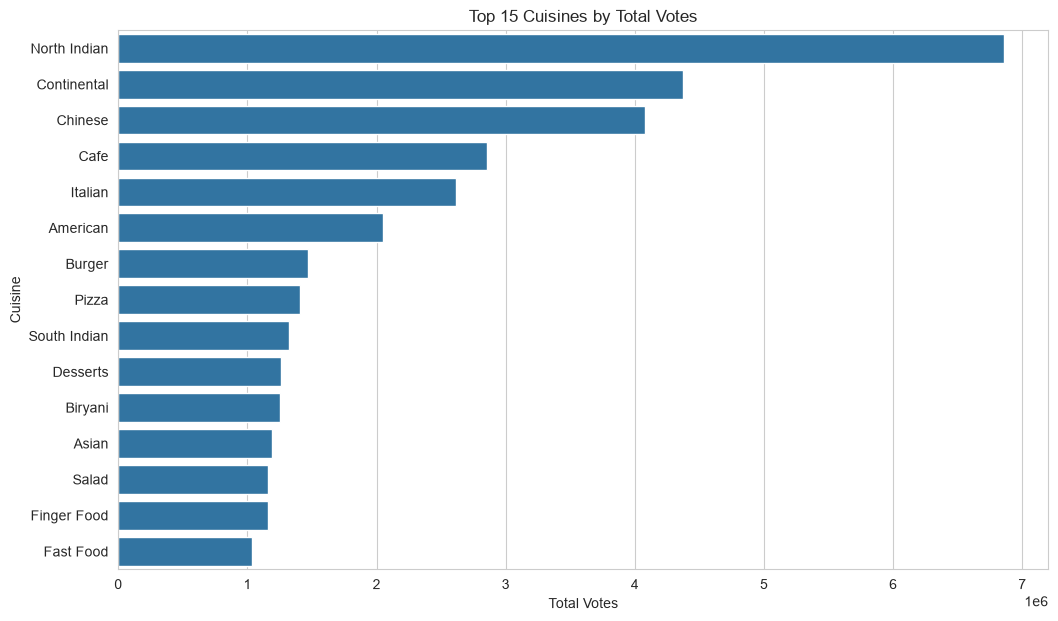

In [ ]:
cuisine_votes = (
    cuisine_df
    .groupby('cuisines')['votes']
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=cuisine_votes.values,
    y=cuisine_votes.index
)

plt.title('Top 15 Cuisines by Total Votes')
plt.xlabel('Total Votes')
plt.ylabel('Cuisine')

plt.show()

In [ ]:
numeric_columns = [
    'rate',
    'votes',
    cost_col,
    'online_order',
    'book_table'
]

correlation = df[numeric_columns].corr(
    method='pearson'
)

print(correlation)

                             rate  votes  approx_cost(for two people)  \
rate                         1.00   0.43                         0.39   
votes                        0.43   1.00                         0.38   
approx_cost(for two people)  0.39   0.38                         1.00   
online_order                 0.07   0.03                        -0.08   
book_table                   0.42   0.41                         0.62   

                             online_order  book_table  
rate                                 0.07        0.42  
votes                                0.03        0.41  
approx_cost(for two people)         -0.08        0.62  
online_order                         1.00        0.00  
book_table                           0.00        1.00  


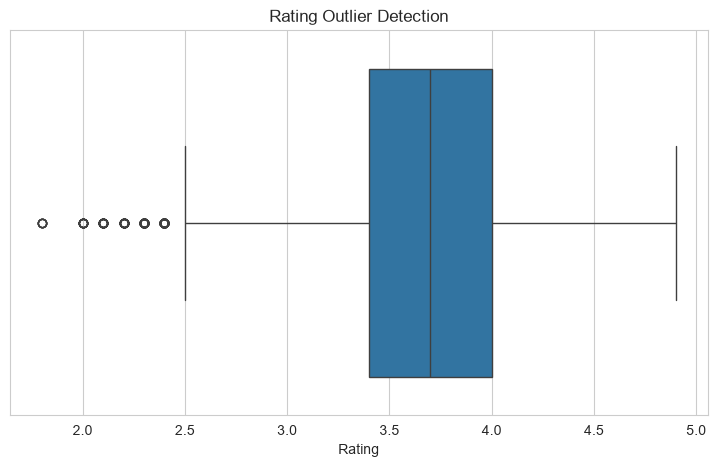

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    x=df['rate']
)

plt.title('Rating Outlier Detection')
plt.xlabel('Rating')

plt.show()

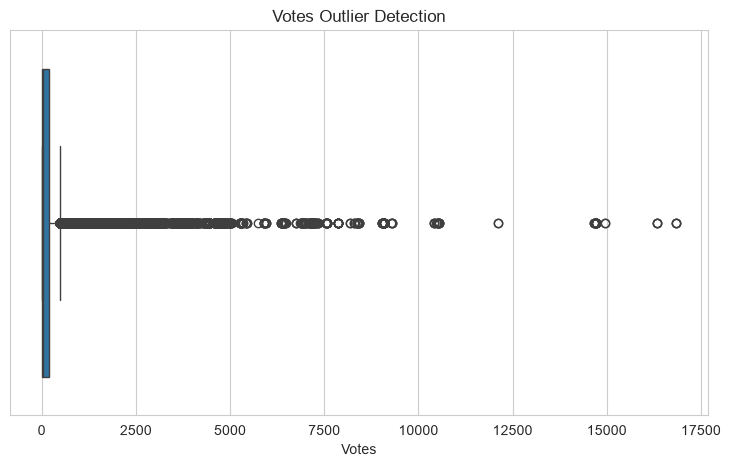

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    x=df['votes']
)

plt.title('Votes Outlier Detection')
plt.xlabel('Votes')

plt.show()

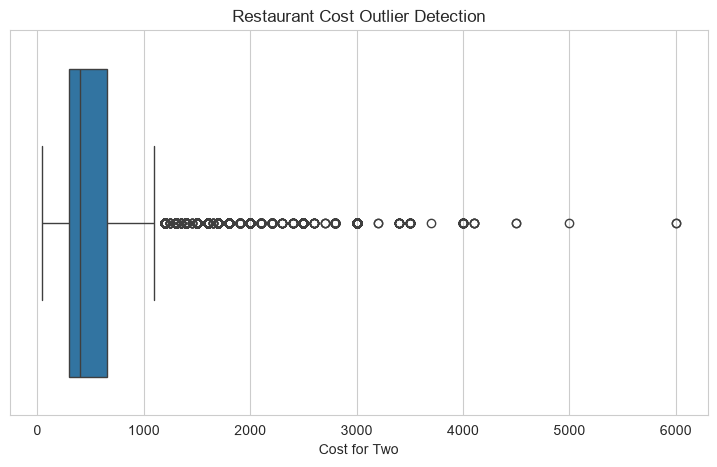

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    x=df[cost_col]
)

plt.title('Restaurant Cost Outlier Detection')
plt.xlabel('Cost for Two')

plt.show()

In [ ]:
def detect_outliers(data, column):

    Q1 = data[column].quantile(0.25)

    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR

    upper_limit = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower_limit) |
        (data[column] > upper_limit)
    ]

    print("Column:", column)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Limit:", lower_limit)
    print("Upper Limit:", upper_limit)
    print("Number of Outliers:", len(outliers))

    return outliers

In [ ]:
vote_outliers = detect_outliers(
    df.dropna(subset=['votes']),
    'votes'
)

display(vote_outliers.head())

Column: votes
Q1: 7.0
Q3: 198.0
IQR: 191.0
Lower Limit: -279.5
Upper Limit: 484.5
Number of Outliers: 6961


,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city),rate_original,rating_category,price_category,online_order_label,table_booking_label
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,1,1,4.10,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari,4.1/5,Excellent,Affordable,Online Available,Booking Available
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,1,0,4.10,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari,4.1/5,Excellent,Affordable,Online Available,Booking Not Available
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,1,0,3.80,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari,3.8/5,Good,Affordable,Online Available,Booking Not Available
7,https://www.zomato.com/bangalore/onesta-banash...,"2469, 3rd Floor, 24th Cross, Opposite BDA Comp...",Onesta,1,1,4.60,2556,080 48653961\r\n080 48655715,Banashankari,"Casual Dining, Cafe","Farmhouse Pizza, Chocolate Banana, Virgin Moji...","Pizza, Cafe, Italian",600,"[('Rated 5.0', 'RATED\n I personally really l...",[],Cafes,Banashankari,4.6/5,Excellent,Affordable,Online Available,Booking Available
9,https://www.zomato.com/bangalore/smacznego-ban...,"2470, 21 Main Road, 25th Cross, Banashankari, ...",Smacznego,1,0,4.20,504,+91 9945230807\r\n+91 9743804471,Banashankari,Cafe,"Waffles, Pasta, Coleslaw Sandwich, Choco Waffl...","Cafe, Mexican, Italian, Momos, Beverages",550,"[('Rated 4.0', ""RATED\n Easy to locate\nVFM 3...",[],Cafes,Banashankari,4.2/5,Excellent,Affordable,Online Available,Booking Not Available


In [ ]:
cost_outliers = detect_outliers(
    df.dropna(subset=[cost_col]),
    cost_col
)

display(cost_outliers.head())

Column: approx_cost(for two people)
Q1: 300.0
Q3: 650.0
IQR: 350.0
Lower Limit: -225.0
Upper Limit: 1175.0
Number of Outliers: 4764


,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city),rate_original,rating_category,price_category,online_order_label,table_booking_label
67,https://www.zomato.com/gustoesbeerhouse?contex...,"10, 30th Main, Deve Gowda Petrol Bunk Road, 3r...",Gustoes Beer House,0,0,4.10,868,080 49653521,Banashankari,Pub,"Beer, Wedges, Pizza, Nachos, Salads, Papaya Sa...","Continental, Italian, Mexican, North Indian, C...",1200,"[('Rated 5.0', 'RATED\n Has a really calm roo...",[],Delivery,Banashankari,4.1/5,Excellent,Moderate,Online Not Available,Booking Not Available
166,https://www.zomato.com/bangalore/patio-805-jay...,"805, Ground Floor, 35C Cross, 9th Main, 4th Bl...",Patio 805,1,1,4.10,364,+91 8884999805,Jayanagar,Casual Dining,"Noodles, Laksa Soup, Coffee, Veg Fritters, Veg...","Thai, Vietnamese, Asian, Chinese",1200,"[('Rated 4.0', ""RATED\n The number of good re...",[],Delivery,Banashankari,4.1/5,Excellent,Moderate,Online Available,Booking Available
207,https://www.zomato.com/bangalore/chutney-chang...,"Cosmopolitan Club, 22nd Cross, 3rd Block, Jaya...",Chutney Chang,1,1,4.10,2339,080 22443007\r\n+91 9901967373,Jayanagar,Casual Dining,"Veg Momos, Brownie Chocolate, Palak Chaat, Mut...","North Indian, Chinese, BBQ",1500,"[('Rated 4.0', 'RATED\n Great place for team ...",[],Delivery,Banashankari,4.1/5,Excellent,Moderate,Online Available,Booking Available
217,https://www.zomato.com/bangalore/toscano-jayan...,"359/38,Next to Fabindia, 7th Cross, 1st Block,...",Toscano,1,1,4.30,1129,080 41558423\r\n+91 7619320074,Jayanagar,Casual Dining,"Pizza, Pasta, Salads, Calamari, Ravioli, Pumpk...","Italian, Salad",1300,"[('Rated 4.0', 'RATED\n Saturday Night Dinner...",[],Delivery,Banashankari,4.3/5,Excellent,Moderate,Online Available,Booking Available
278,https://www.zomato.com/bangalore/gufha-the-pre...,"The President Hotel, 79/8, Diagonal Road, 3rd ...",Gufha - The President Hotel,1,1,4.10,1875,080 41808777\r\n+91 9900265022,Jayanagar,Casual Dining,"Cocktails, Paneer Tikka, Rasmalai, Rabri, Masa...","North Indian, Afghani, Mughlai",1200,"[('Rated 5.0', 'RATED\n From the dark Caves, ...",[],Delivery,Banashankari,4.1/5,Excellent,Moderate,Online Available,Booking Available


In [ ]:
online_yes = df.loc[
    df['online_order'] == 1,
    'rate'
].dropna()

online_no = df.loc[
    df['online_order'] == 0,
    'rate'
].dropna()

# Independent Welch's t-test
t_stat, p_value = stats.ttest_ind(
    online_yes,
    online_no,
    equal_var=False
)

print("Online ordering average rating:", online_yes.mean())

print("No online ordering average rating:", online_no.mean())

print("T-statistic:", t_stat)

print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: Statistically significant rating difference.")
else:
    print("Fail to reject H0: No statistically significant difference.")

Online ordering average rating: 3.7224399029625816
No online ordering average rating: 3.659070475136593
T-statistic: 13.592564022448219
P-value: 6.087362088377593e-42
Reject H0: Statistically significant rating difference.


In [ ]:
booking_yes = df.loc[
    df['book_table'] == 1,
    'rate'
].dropna()

booking_no = df.loc[
    df['book_table'] == 0,
    'rate'
].dropna()

t_stat, p_value = stats.ttest_ind(
    booking_yes,
    booking_no,
    equal_var=False
)

print("Booking available average:", booking_yes.mean())

print("Booking unavailable average:", booking_no.mean())

print("T-statistic:", t_stat)

print("P-value:", p_value)

if p_value < 0.05:
    print("Significant difference in ratings.")
else:
    print("No statistically significant difference.")

Booking available average: 4.143464467005076
Booking unavailable average: 3.621469981052572
T-statistic: 118.79517731866773
P-value: 0.0
Significant difference in ratings.


In [ ]:
anova_data = df[
    ['price_category', 'rate']
].dropna()

groups = [
    group['rate'].values
    for _, group in anova_data.groupby(
        'price_category',
        observed=True
    )
]

f_stat, p_value = stats.f_oneway(*groups)

print("F-statistic:", f_stat)

print("P-value:", p_value)

if p_value < 0.05:
    print("At least one price category has a different mean rating.")
else:
    print("No statistically significant difference detected.")

F-statistic: 2048.9787892506242
P-value: 0.0
At least one price category has a different mean rating.


In [ ]:
top_10_votes = (
    df.groupby('name')
    .agg(
        total_votes=('votes', 'sum'),
        avg_rating=('rate', 'mean'),
        avg_cost=(cost_col, 'mean')
    )
    .sort_values(
        by='total_votes',
        ascending=False
    )
    .head(10)
)

display(top_10_votes)

,total_votes,avg_rating,avg_cost
name,,,
Onesta,347520,4.41,600.00
Truffles,301059,4.60,900.00
Empire Restaurant,229808,4.03,685.21
Hammered,180602,4.62,1272.34
The Black Pearl,172122,4.73,1427.78
Meghana Foods,129557,4.34,633.33
Barbeque Nation,108425,4.49,1600.00
Smally's Resto Cafe,102877,4.17,650.00
Byg Brewski Brewing Company,99531,4.90,1600.00


In [ ]:
restaurant_ratings = (
    df.groupby('name')
    .agg(
        avg_rating=('rate', 'mean'),
        total_votes=('votes', 'sum'),
        cost=(cost_col, 'mean')
    )
)

top_rated = restaurant_ratings[
    restaurant_ratings['total_votes'] >= 100
]

top_rated = top_rated.sort_values(
    by='avg_rating',
    ascending=False
).head(10)

display(top_rated)

,avg_rating,total_votes,cost
name,,,
SantÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂ© Spa Cuisine,4.90,246,1000.00
Byg Brewski Brewing Company,4.90,99531,1600.00
Asia Kitchen By Mainland China,4.90,42273,1500.00
Punjab Grill,4.87,9660,2000.00
Belgian Waffle Factory,4.84,24882,400.00
O.G. Variar & Sons,4.80,2317,200.00
Flechazo,4.80,29956,1400.00
The Pizza Bakery,4.80,10523,1200.00
AB's - Absolute Barbecues,4.79,86418,1568.42


In [ ]:
location_online = (
    df[df['location'] != 'Unknown']
    .groupby('location')
    .agg(
        total_restaurants=('name', 'count'),
        online_restaurants=('online_order', 'sum')
    )
)

location_online['online_percentage'] = (
    location_online['online_restaurants'] /
    df.groupby('location')['online_order'].count()
    .reindex(location_online.index)
) * 100

location_online = location_online.sort_values(
    by='online_percentage',
    ascending=False
)

display(location_online.head(15))

,total_restaurants,online_restaurants,online_percentage
location,,,
Rajarajeshwari Nagar,2,2,100.00
Kanakapura Road,19,17,89.47
Nagawara,187,162,86.63
Kumaraswamy Layout,195,165,84.62
Rammurthy Nagar,32,27,84.38
Yelahanka,6,5,83.33
"Varthur Main Road, Whitefield",117,97,82.91
Kaggadasapura,101,79,78.22
Yeshwantpur,119,93,78.15


In [ ]:
service_analysis = (
    df.groupby(
        ['online_order_label', 'table_booking_label'],
        dropna=False
    )
    .agg(
        restaurant_count=('name', 'count'),
        avg_rating=('rate', 'mean'),
        avg_votes=('votes', 'mean'),
        avg_cost=(cost_col, 'mean')
    )
)

display(service_analysis)

restaurant_count  avg_rating  \
online_order_label   table_booking_label                                   
Online Available     Booking Available                  3805        4.13   
                     Booking Not Available             26639        3.66   
Online Not Available Booking Available                  2644        4.16   
                     Booking Not Available             18629        3.55   

                                            avg_votes  avg_cost  
online_order_label   table_booking_label                         
Online Available     Booking Available        1160.26   1090.53  
                     Booking Not Available     185.15    444.41  
Online Not Available Booking Available        1128.23   1531.56  
                     Booking Not Available     125.71    464.67

In [ ]:
location_cuisine = (
    cuisine_df.groupby(
        ['location', 'cuisines']
    )
    .agg(
        restaurant_count=('name', 'count'),
        avg_rating=('rate', 'mean'),
        total_votes=('votes', 'sum')
    )
    .reset_index()
)

location_cuisine = location_cuisine[
    location_cuisine['restaurant_count'] >= 5
]

location_cuisine = location_cuisine.sort_values(
    by='avg_rating',
    ascending=False
)

display(location_cuisine.head(20))

,location,cuisines,restaurant_count,avg_rating,total_votes
1921,Malleshwaram,Tex-Mex,6,4.80,38707
1877,Malleshwaram,BBQ,8,4.79,41390
1088,JP Nagar,Mediterranean,8,4.71,30822
1409,Koramangala 1st Block,European,7,4.70,25358
575,Cunningham Road,Japanese,34,4.69,161365
2107,Old Airport Road,American,8,4.65,73316
2269,Residency Road,BBQ,9,4.64,35835
1775,Lavelle Road,Juices,11,4.60,27565
1806,MG Road,Cantonese,6,4.60,14122
2848,Whitefield,African,5,4.60,2954


In [ ]:
cluster_data = df[
    ['rate', 'votes', cost_col]
].copy()

# Remove missing values
cluster_data = cluster_data.dropna()

print(cluster_data.shape)

display(cluster_data.head())

(41418, 3)


,rate,votes,approx_cost(for two people)
0,4.10,775,800
1,4.10,787,800
2,3.80,918,800
3,3.70,88,300
4,3.80,166,600


In [ ]:
cluster_data['votes_log'] = np.log1p(
    cluster_data['votes']
)

cluster_data['cost_log'] = np.log1p(
    cluster_data[cost_col]
)

cluster_features = cluster_data[
    ['rate', 'votes_log', 'cost_log']
]

In [ ]:
cluster_data['votes_log'] = np.log1p(
    cluster_data['votes']
)

cluster_data['cost_log'] = np.log1p(
    cluster_data[cost_col]
)

cluster_features = cluster_data[
    ['rate', 'votes_log', 'cost_log']
]

In [ ]:
scaler = StandardScaler()

scaled_features = scaler.fit_transform(
    cluster_features
)

print(scaled_features.shape)

(41418, 3)


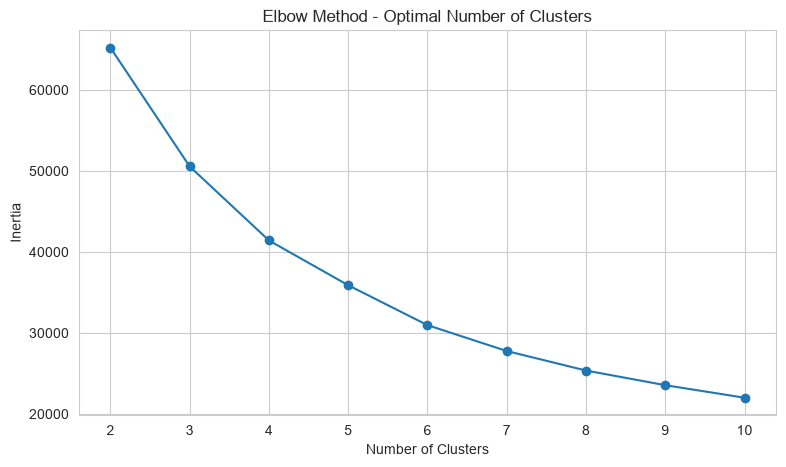

In [ ]:
inertia_values = []

K_values = range(2, 11)

for k in K_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(scaled_features)

    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(9, 5))

plt.plot(
    K_values,
    inertia_values,
    marker='o'
)

plt.title('Elbow Method - Optimal Number of Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')

plt.xticks(list(K_values))

plt.show()

In [ ]:
silhouette_scores = []

for k in range(2, 8):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(
        scaled_features
    )

    score = silhouette_score(
        scaled_features,
        labels
    )

    silhouette_scores.append(score)

    print(
        f"Clusters: {k}, "
        f"Silhouette Score: {score:.4f}"
    )

Clusters: 2, Silhouette Score: 0.4034
Clusters: 3, Silhouette Score: 0.3032
Clusters: 4, Silhouette Score: 0.3014
Clusters: 5, Silhouette Score: 0.3020
Clusters: 6, Silhouette Score: 0.2898
Clusters: 7, Silhouette Score: 0.2753


In [ ]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

cluster_data['cluster'] = kmeans.fit_predict(
    scaled_features
)

print(cluster_data['cluster'].value_counts())

cluster
2    13971
1    11235
0     9529
3     6683
Name: count, dtype: int64


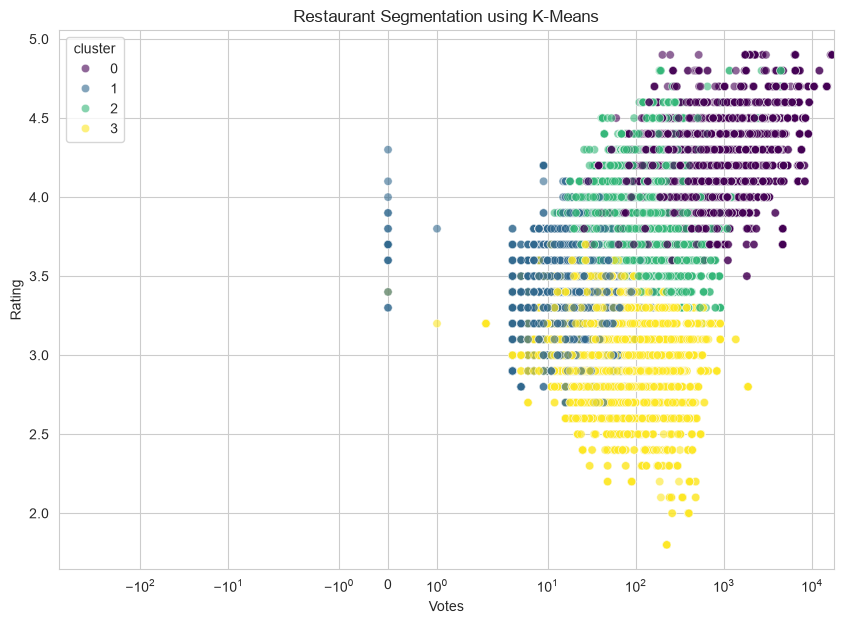

In [ ]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=cluster_data,
    x='votes',
    y='rate',
    hue='cluster',
    palette='viridis',
    alpha=0.6
)

plt.xscale('symlog')

plt.title('Restaurant Segmentation using K-Means')
plt.xlabel('Votes')
plt.ylabel('Rating')

plt.show()

In [ ]:
cluster_summary = (
    cluster_data
    .groupby('cluster')
    .agg(
        avg_rating=('rate', 'mean'),
        avg_votes=('votes', 'mean'),
        avg_cost=(cost_col, 'mean'),
        restaurant_count=('rate', 'count')
    )
)

display(cluster_summary)

,avg_rating,avg_votes,avg_cost,restaurant_count
cluster,,,,
0,4.17,1197.40,1185.27,9529
1,3.45,19.50,274.68,11235
2,3.87,172.82,462.73,13971
3,3.10,78.44,619.61,6683


In [ ]:
total_restaurants = df['name'].nunique()

total_records = len(df)

average_rating = df['rate'].mean()

average_cost = df[cost_col].mean()

total_votes = df['votes'].sum()

online_order_percentage = (
    df['online_order'].mean() * 100
)

table_booking_percentage = (
    df['book_table'].mean() * 100
)

print("========== ZOMATO BUSINESS SUMMARY ==========")

print("Total Restaurant Records:", total_records)

print("Unique Restaurant Names:", total_restaurants)

print("Average Restaurant Rating:", round(average_rating, 2))

print("Average Cost for Two:", round(average_cost, 2))

print("Total Customer Votes:", total_votes)

print(
    "Online Ordering Percentage:",
    round(online_order_percentage, 2), "%"
)

print(
    "Table Booking Percentage:",
    round(table_booking_percentage, 2), "%"
)

========== ZOMATO BUSINESS SUMMARY ==========
Total Restaurant Records: 51717
Unique Restaurant Names: 8792
Average Restaurant Rating: 3.7
Average Cost for Two: 555.43
Total Customer Votes: 14671985
Online Ordering Percentage: 58.87 %
Table Booking Percentage: 12.47 %
